# TrackCast: exploratory analysis (Phase 6)

The proposal's exploratory step: the delay distribution, cascading delay trajectories, fog and monsoon
slowdowns, and schedule recovery at junctions vs minor halts, plus per-class and per-corridor profiles
(mean delay, recovery rate, congestion sensitivity).

All logic is in `src/trackcast/eda.py`; this notebook only loads its tables and draws its figures.
Build them first (full year shown here; drop `--full` for the dev sample):

```
python -m trackcast.profiles --full
python -m trackcast.eda --full
```

*Change* = delay at a stop minus the delay at the previous observed stop of the same run (negative = time
recovered). *Late* = more than 15 min.

In [1]:
%matplotlib inline
import pandas as pd
from IPython.display import display

from trackcast import config as C
from trackcast import eda as E

FULL = (C.EDA_DIR / "hist.parquet").exists()
t = E.load(full=FULL)
pd.set_option("display.float_format", "{:,.2f}".format)
print("data:", "full year (clean.parquet)" if FULL else "dev sample (sample.parquet)")

data: full year (clean.parquet)


## 1. Delay distribution

Delays are whole minutes, so the 1-minute histogram gives exact quantiles and moments for both scales. The
raw distribution has a spike at 0 and a long right tail. log1p makes the late part close to symmetric, and
the on-time spike is left for Stage 1 of the hurdle model.

,value
arrivals,"36,025,806.00"
zero_pct,15.32
late_pct,50.59
over_3h_pct,3.06
mean,36.05
sd,66.24
median,16.00
p90,88.00
p99,309.00
max,"1,440.00"


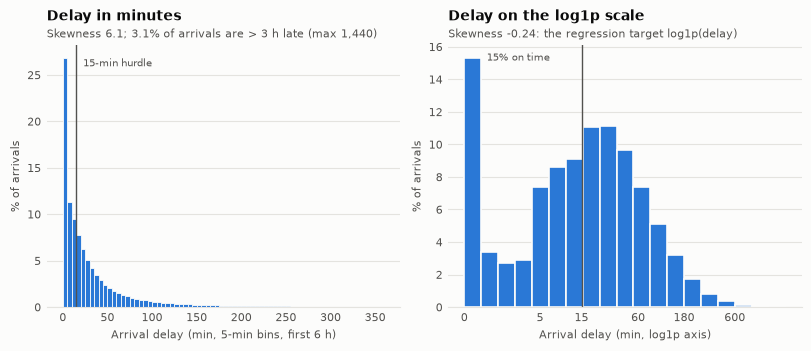

In [2]:
display(pd.Series(E.distribution_summary(t["hist"], t["moments"])).round(2).to_frame("value"))
E.fig_delay_distribution(t)

## 2. Cascading delay trajectories

**How far does a delay cascade?** For every observed stop, the delay h observed stops later in the same
run, grouped by the delay at the start (Phase 4 cascade table).

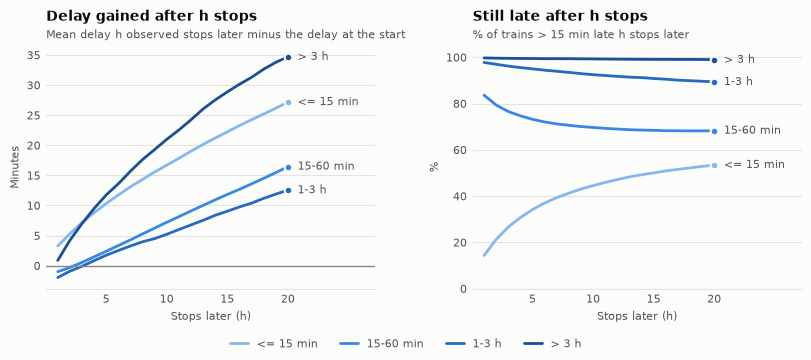

In [3]:
E.fig_cascade(t)

In [4]:
cas = t["p4_cascade"]
cas[cas["h"].isin([1, 5, 10, 20])].pivot(index="h", columns="initial_delay", values="late_pct_h")

initial_delay,"(15, 60]","(60, 180]",<= 15,> 180
h,,,,
1,83.63,97.76,14.31,99.73
5,73.18,95.00,34.16,99.47
10,69.66,92.48,44.52,99.29
20,68.21,89.38,53.43,98.99


**Delay along the route.** Left: mean delay by the share of the route covered, for the train classes the
proposal names. Right: the four long-distance corridors (zone of origin to zone of terminus, both
directions) with the most arrivals; a corridor's line stops where fewer than a quarter of its trains still
run.

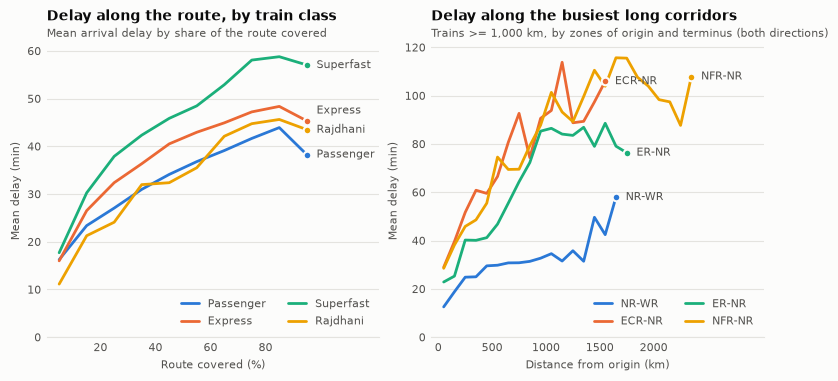

In [5]:
E.fig_trajectories(t)

**Profiles by train class and by corridor.** *Recovery* = % of arrivals late at the previous stop whose
delay falls on arrival. *Congestion slope* = minutes of delay gained over one scheduled segment per 10 extra
trains scheduled at the arrival station in that hour (least squares, pooled).

In [6]:
cols = ["n_trains", "n_runs", "n_obs", "mean_delay", "late_pct", "recovery_pct_when_late",
        "mean_change_when_late", "congestion_slope_per10"]
pt = E.profile_rates(t["profile_type"])
pt.index = pt.index.map(lambda c: E.TYPE_LABELS.get(c, c))
pt[cols].sort_values("n_runs", ascending=False)

,n_trains,n_runs,n_obs,mean_delay,late_pct,recovery_pct_when_late,mean_change_when_late,congestion_slope_per10
type_code,,,,,,,,
Passenger,3056,1028942,17570581,32.75,48.53,39.50,-0.78,-4.55
Express,2056,471263,12867733,37.48,53.48,44.69,-1.82,-2.68
Superfast,1354,247001,4803960,44.04,52.73,46.86,-0.73,-1.06
Vande Bharat (T18),194,42631,328173,15.29,26.55,58.49,-3.56,-0.30
Shatabdi,42,13162,97828,15.04,23.58,58.75,-2.55,-0.43
Premium / special,106,11449,150469,96.12,54.94,44.03,8.22,3.81
Rajdhani,48,9722,112788,32.36,36.41,58.97,0.26,1.92
Garib Rath,52,6114,94274,52.52,51.77,45.77,0.10,-1.93


In [7]:
pc = E.profile_rates(t["profile_corridor"])
pc = pc[pc["n_runs"] >= C.EDA_MIN_OBS["profile_runs"][1 if FULL else 0]]
pc[cols].sort_values("n_runs", ascending=False).head(15)

,n_trains,n_runs,n_obs,mean_delay,late_pct,recovery_pct_when_late,mean_change_when_late,congestion_slope_per10
corridor,,,,,,,,
within NR,566,182956,2749713,31.93,51.87,34.42,0.27,-1.81
within SR,484,156565,2802771,12.96,30.46,48.14,-3.59,-2.70
within WR,373,117875,1832649,11.21,25.12,54.12,-3.12,-0.87
within ECR,310,100108,2081389,49.17,65.23,41.50,-1.08,-8.05
within ER,277,93622,1470742,18.59,35.59,35.23,-0.72,-2.82
within SCR,282,87019,1655831,37.47,60.43,42.41,-3.98,-4.22
within SWR,205,67024,1070375,15.20,34.26,48.70,-3.26,-2.69
within NFR,196,60281,1101540,30.41,52.52,41.85,-1.57,-6.98
within NER,183,58905,1084759,44.09,51.08,41.55,-0.06,-2.39


**One train, every run.** The same train on the same timetable ends its route hours apart from one day to
the next. A train's or a station's average says little about a single run; the run's own upstream delay
does, which is why lag features dominate the model.

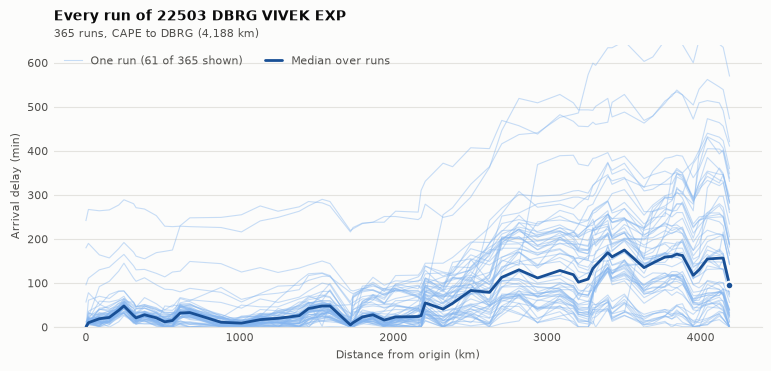

In [8]:
E.fig_example_train(t)

In [9]:
pd.Series(E.example_stats(t["example_runs"])).to_frame("value")

,value
train_no,22503
train_name,DBRG VIVEK EXP
runs,365
first_station,CAPE
first_p10,0.00
first_median,0.00
first_p90,6.60
last_station,DBRG
last_p10,0.00
last_median,95.50


## 3. Seasonal slowdowns: fog and monsoon

The data has no weather observations, so these are season effects. Comparing fog-prone zones with the rest
in the same months (difference in differences) removes what is network-wide, such as winter timetables and
holiday traffic.

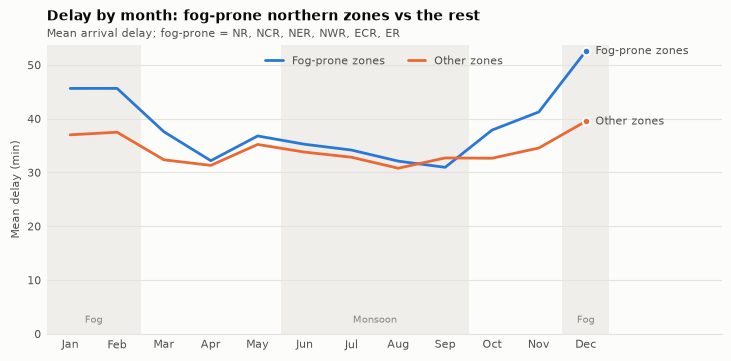

In [10]:
E.fig_season_month(t)

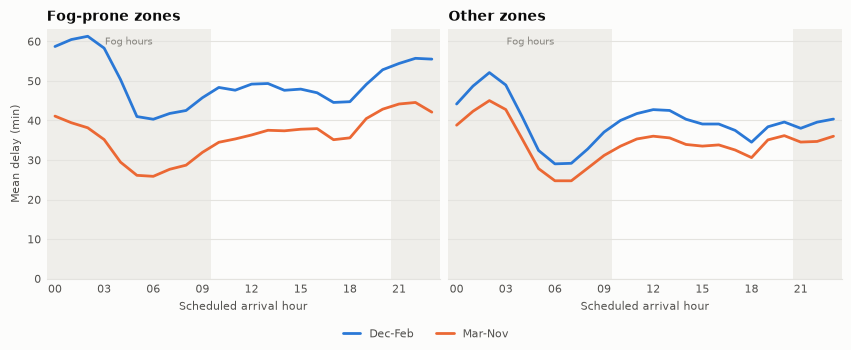

In [11]:
E.fig_fog_hour(t)

In [12]:
seasons = E.season_tables(t["month_hour_zone"], C.EDA_MIN_OBS["zone"][1 if FULL else 0])
pd.DataFrame(E.did_numbers(seasons["fog_did"], seasons["fog_night"])).round(2)

,mean_delay,mean_change
fog_zones_uplift,12.71,0.77
other_zones_uplift,5.12,0.14
did,7.59,0.63
night_uplift,15.06,1.28
day_uplift,10.54,0.29
night_minus_day,4.52,0.99


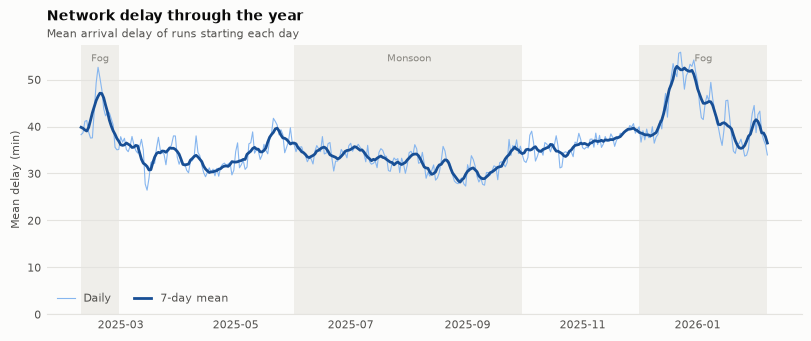

In [13]:
E.fig_daily(t)

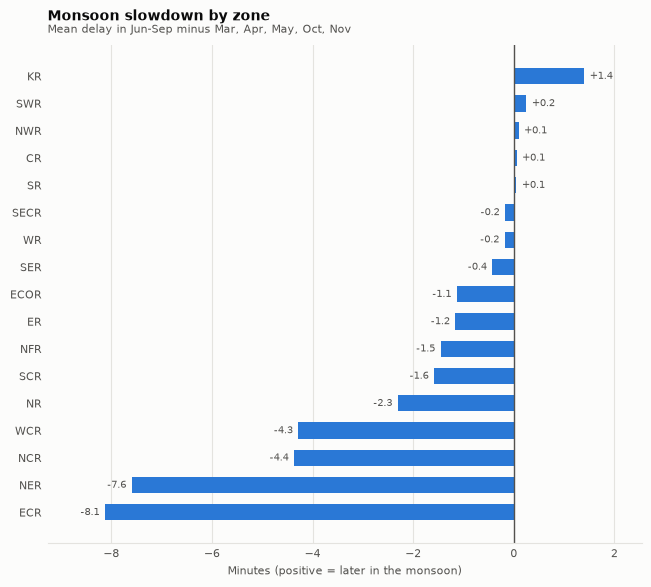

In [14]:
E.fig_monsoon_zone(t)

In [15]:
seasons["monsoon_zone"].set_index("station_zone")[["n_monsoon", "mean_delay_dry", "mean_delay_monsoon",
                                                   "delay_diff", "change_diff"]]

,n_monsoon,mean_delay_dry,mean_delay_monsoon,delay_diff,change_diff
station_zone,,,,,
KR,78320,43.45,44.85,1.40,-0.05
SWR,561999,18.89,19.14,0.25,-0.01
NWR,716743,17.87,17.96,0.09,0.01
CR,546769,36.76,36.82,0.05,0.18
SR,1162941,15.87,15.92,0.05,-0.01
SECR,442307,55.01,54.83,-0.17,0.16
WR,894101,14.30,14.12,-0.18,-0.01
SER,517654,52.32,51.90,-0.43,0.08
ECOR,474994,51.10,49.97,-1.13,0.08


## 4. Schedule recovery: junctions vs minor halts

Junction = station name contains `JN`; major station = any other station with at least 100 distinct
scheduled trains a day; the rest are minor halts. Stations Phase 4 flags as timetable errors are left out.
The right panel compares junctions with other stations of the same scheduled traffic.

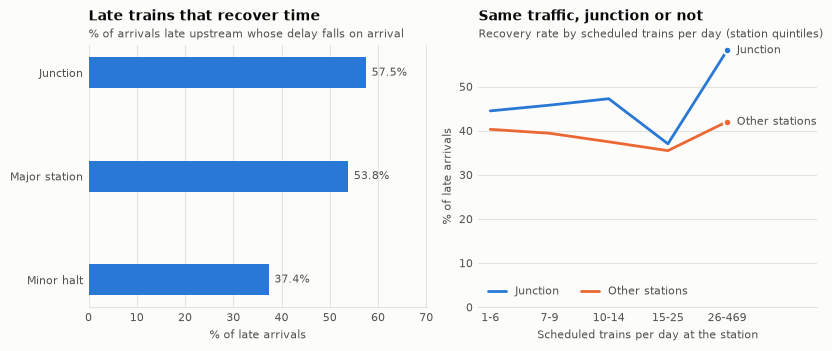

In [16]:
E.fig_recovery(t)

In [17]:
display(E.station_class_rates(t["station_classes"]).set_index("station_class"))
E.recovery_by_traffic(t["station_classes"]).pivot(index="traffic", columns="junction", values="recovery_pct")

,stations,arrivals,mean_delay,late_pct,late_arrivals_upstream,recovery_pct,mean_change_when_late,median_trains_day,median_dwell_min
station_class,,,,,,,,,
Junction,362,6035979,37.52,45.91,2823887,57.53,-4.49,67.00,2.00
Major station,146,3812591,40.94,49.66,1906313,53.84,-3.47,136.00,2.00
Minor halt,7483,25803402,34.89,51.67,12700502,37.36,0.25,10.00,1.00


junction,Junction,Other stations
traffic,,
1-6,44.48,40.30
10-14,47.24,37.47
15-25,37.02,35.47
26-469,58.21,42.05
7-9,45.78,39.41


## 5. Congestion

Delay change over one scheduled segment by the number of trains scheduled at the arrival station in that
hour. Busy stations are also the big stations with timetable allowances, so this is an association.

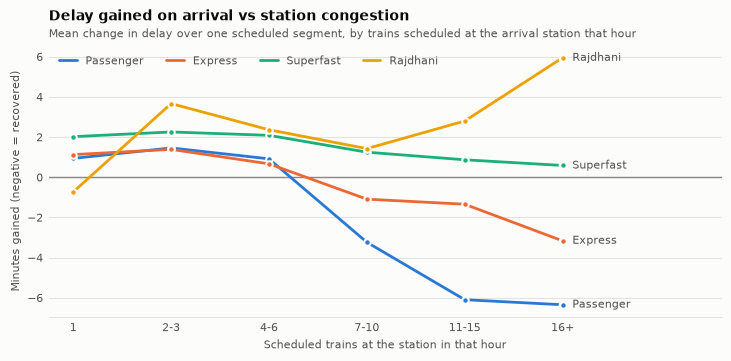

In [18]:
E.fig_congestion(t)

In [19]:
cr = E.congestion_rates(t["congestion_type"], C.EDA_MIN_OBS["bin"][1 if FULL else 0])
cr[cr["type_code"].isin(E.FIGURE_TYPES)].pivot(index="congestion", columns="type_code", values="mean_change") \
    .reindex(E.congestion_labels())

type_code,EXP-TRAINS,PASS-TRAINS,RAJ-TRAINS,SF-TRAINS
congestion,,,,
1,1.12,0.94,-0.73,2.02
2-3,1.39,1.46,3.66,2.25
4-6,0.66,0.91,2.36,2.08
7-10,-1.09,-3.24,1.42,1.25
11-15,-1.35,-6.10,2.80,0.87
16+,-3.17,-6.35,5.95,0.58
